# 62장 · 에이전트에 MCP 도구 연결하기

에이전트가 ‘주말 운영 시간’을 물으면 어느 연결에서 도구를 실행할지 앱이 정합니다. 61장의 MCP 서버를 그대로 쓰면서 실제 LangChain 도구 하나가 현재 열린 MCP 세션을 통해 시간을 받아오도록 연결합니다.

실행을 확인한 커널은 Python 3.12.15입니다. 예제에 사용한 외부 패키지는 langchain 1.4.6, langchain-core 1.6.12, langsmith 0.14.11, mcp 1.30.0입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.

## 세션 수명 안에 도구 연결하기

제공 셀에는 두 가지 코드가 있습니다. 위쪽은 서버의 시간표이고, 다음 셀의 어댑터는 LangChain 도구의 day 인자를 MCP 요청으로 바꿉니다. 메모리 전송이므로 원격 서버 배포나 인증 설정 없이 왕복을 확인할 수 있습니다.


### 셀 01 · 제공 셀 · 61장의 시간표 서버

같은 서버, 같은 두 요일, 같은 자료 버전을 유지합니다.

In [1]:
from typing import Literal
from mcp.server.fastmcp import FastMCP
from mcp.shared.memory import create_connected_server_and_client_session

server = FastMCP("course-library-v1", log_level="ERROR")
hours = {"weekday": "09:00~18:00", "weekend": "10:00~16:00"}

@server.tool()
def get_library_hours(day: Literal["weekday", "weekend"]) -> dict[str, str]:
    """가상 도서관의 평일 또는 주말 운영 시간을 조회합니다."""
    return {"day": day, "hours": hours[day], "source": "수업용 가상 도서관"}

지금은 도구를 등록했습니다. 다음 셀에서 연결을 열 때까지 요청 횟수는 늘지 않습니다.

### 셀 02 · LangChain 도구에서 MCP 호출하기

ainvoke로 호출한 도구가 세션을 통해 받은 운영 시간만 돌려주게 합니다.

에이전트에는 lookup이라는 도구가 보입니다. lookup이 받은 day를 session.call_tool로 넘길 때 서버에는 get_library_hours라는 이름을 보냅니다. 서버 결과의 시간이 도구 메시지 내용으로 돌아오는 지점을 찾아보세요.

In [2]:
from langchain_core.tools import tool

def make_lookup(session):
    @tool
    async def lookup(day: Literal["weekday", "weekend"]) -> str:
        """가상 도서관의 운영 시간을 MCP로 조회한다."""
        reply = await session.call_tool("get_library_hours", {"day": day})
        if reply.isError:
            raise ValueError("remote_tool_error")
        data = reply.structuredContent
        if data["day"] != day:
            raise ValueError("result_day_mismatch")
        return data["hours"]
    return lookup

async with create_connected_server_and_client_session(server) as session:
    lookup = make_lookup(session)
    result = await lookup.ainvoke({"day": "weekend"})
print(result)

10:00~16:00


LangChain 도구가 반환한 10:00~16:00은 MCP 서버의 시간표 값입니다. 세션을 닫은 뒤 도구만 보관하면 요청 경로가 끊어집니다. 실제 에이전트는 도구를 등록한 뒤에도 세션이 열린 동안 실행해야 합니다.

## 응답 모양이 맞아도 요일이 틀릴 수 있습니다

운영 시간이 문자열인지 확인하는 것만으로 어느 날의 시간인지 보장할 수 없습니다. 받은 요일과 요청한 요일을 같이 검사합니다. 시간 초과는 이 검사보다 앞서 통신 단계에서 처리해야 합니다.

<!-- motion:weekday-dial -->
**형식이 맞는 시간표도 틀린 답일 수 있을까요?**

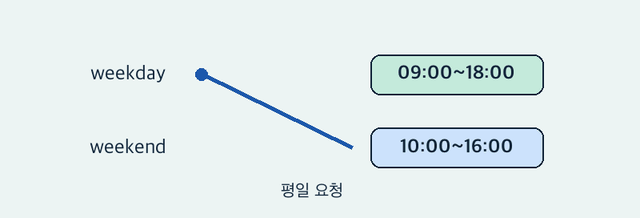

평일 요청에 주말 시각을 반환해도 필드 자체는 있을 수 있습니다. 요청한 요일과 맞춰 읽으면 평일에는 09:00~18:00이 대응합니다.
<!-- /motion -->


### 과제 03 · 응답에서 요청 요일 대조하기

주말 요청에 돌아온 응답이 평일입니다. 요일 불일치를 찾아내는 조건을 작성하세요.

In [3]:
received = {'day': 'weekday', 'hours': '09:00~18:00'}
requested = 'weekend'
# 받은 요일이 요청과 같은지 확인하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>received = {&#x27;day&#x27;: &#x27;weekday&#x27;, &#x27;hours&#x27;: &#x27;09:00~18:00&#x27;}
requested = &#x27;weekend&#x27;
print(received[&#x27;day&#x27;] == requested)</code></pre>
<p>실행 결과</p><pre><code>False</code></pre>
<p>False입니다. 이 값을 정상 운영 시간으로 보여 주기 전에 중단해야 합니다. 이미 닫힌 연결을 사용한 경우와 서버가 오류를 보낸 경우, 응답 내용이 요청과 다른 경우를 구분하세요.</p>
</details>

## 에이전트의 도구 요청을 같은 세션에서 처리하기

평일 요청 한 건을 내는 대본 모델을 실제 create_agent에 연결합니다. 최종 답안은 대본에 고정했으므로 도구가 어디에서 무엇을 가져왔는지는 도구 메시지로 확인하세요.


### 셀 04 · MCP 응답을 실제 ToolMessage에서 읽기

lookup에 등록한 실행 함수가 MCP를 한 번 부릅니다. 수업용 모델과 서버 모두 네트워크를 사용하지 않습니다.

In [4]:
from langchain.agents import create_agent
from langchain_core.language_models.fake_chat_models import FakeMessagesListChatModel
from langchain_core.messages import AIMessage
from langsmith import tracing_context

class DemoModel(FakeMessagesListChatModel):
    def bind_tools(self, tools, **kwargs):
        return self

model = DemoModel(responses=[
    AIMessage(content="", tool_calls=[{"name": "lookup", "args": {"day": "weekday"}, "id": "hours-1"}]),
    AIMessage(content="조회가 끝났습니다."),
])
async with create_connected_server_and_client_session(server) as session:
    agent = create_agent(model, tools=[make_lookup(session)])
    with tracing_context(enabled=False):
        state = await agent.ainvoke({"messages": [("user", "평일 운영 시간은?")]})
for message in state["messages"]:
    if message.type == "tool":
        print(message.tool_call_id, message.content)

hours-1 09:00~18:00


hours-1은 에이전트가 요청과 결과를 연결하는 호출 ID입니다. 뒤의 09:00~18:00이 MCP가 반환한 시간입니다. 외부 HTTP 접속 시간이나 원격 인증을 확인한 기록은 아닙니다.

## 돌아보기

같은 평일 질문을 Python 함수와 MCP를 연결한 LangChain 도구에 한 번씩 전달해 시간을 비교해 보세요. 속도 비교가 필요하면 네트워크가 있는 실제 주소에서 따로 측정해야 합니다.

### 셀 04 · 평일 운영 시간이 도구 메시지에 담기는 과정

**평일 조회 요청**　대본 모델이 lookup에 전달할 요일과 호출 ID를 만듭니다.

```
lookup(day="weekday") · id=hours-1
```

**MCP 세션으로 전달**　lookup은 현재 열린 세션에서 서버 도구를 부릅니다.

```
session.call_tool("get_library_hours", {"day": "weekday"})
```

**시간표에서 평일 조회**　서버가 요청 요일과 시간을 돌려줍니다. 어댑터가 요일을 확인하고 hours를 반환합니다.

```
day = weekday
hours = 09:00~18:00
```

**요청과 시간 연결**　도구가 돌려준 시간이 같은 ID의 도구 메시지 본문에 들어갑니다.

```
ToolMessage · tool_call_id=hours-1
content = 09:00~18:00
```

**도구 메시지 출력**　마지막 모델 문장은 대본에 들어 있습니다. 실제로 받은 시간은 메시지의 호출 ID와 함께 출력합니다.

```
hours-1 09:00~18:00
```
